In [1]:
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from tqdm import tqdm

# Drop a half-imported torch._dynamo left by a previous failed torch.compile.
_utils = sys.modules.get("torch._dynamo.utils")
if _utils is not None and not hasattr(_utils, "NP_SUPPORTED_MODULES"):
    for _k in list(sys.modules):
        if _k == "torch._dynamo" or _k.startswith("torch._dynamo."):
            del sys.modules[_k]

MLP: 100%|██████████| 10000/10000 [00:33<00:00, 296.86it/s, loss=0.1827]


FoldNet 1345 p : MSE 1.96e-02 (79.2s) | MLP 1409 p : MSE 1.85e-01 (33.7s)


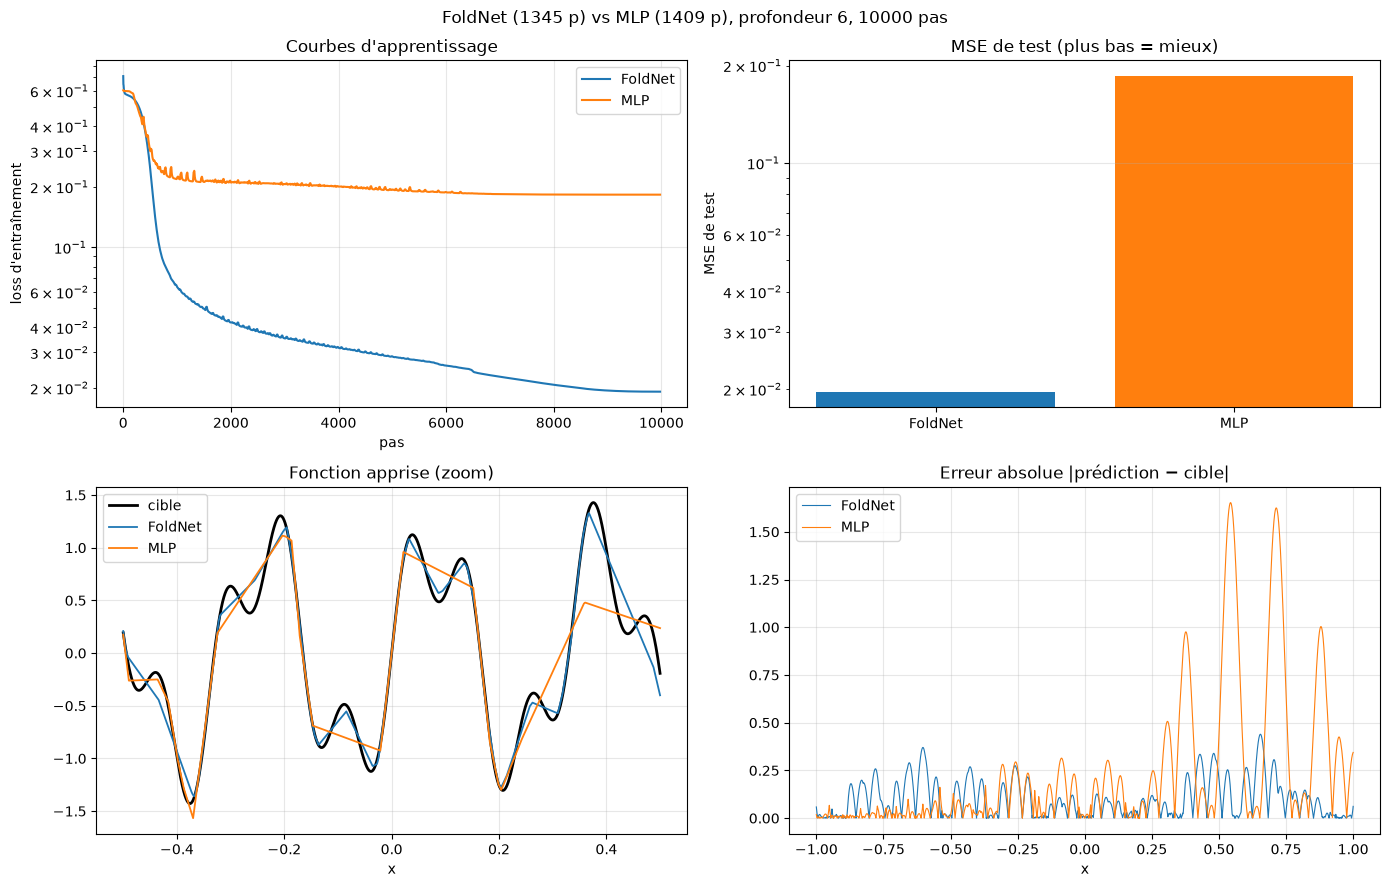

In [7]:
DEV = "cuda" if torch.cuda.is_available() else "cpu"
STEPS, LR, DEPTH = 10000, 3e-3, 6
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

class FoldNet(nn.Module):
    """Couches Pliage : y = | M_l x - t_l |,  M_l = H(v_k)...H(v_1),
    avec H(v)x = x - 2 v (v.x)/(v.v). Les matrices M_l sont calculées en lot."""
    def __init__(self, din, dout, d=32, depth=6, k=2):
        super().__init__()
        self.inp = nn.Linear(din, d)
        self.v = nn.Parameter(torch.randn(depth, k, d))
        self.t = nn.Parameter(0.5 * torch.randn(depth, d))
        self.out = nn.Linear(d, dout)
        self.register_buffer("I", torch.eye(d))
    def forward(self, x):
        u = self.v / (self.v.pow(2).sum(-1, keepdim=True) + 1e-8).sqrt()
        M = self.I.expand(self.v.shape[0], -1, -1)
        for i in range(self.v.shape[1]):
            ui = u[:, i]
            M = M - 2 * ui.unsqueeze(-1) @ (ui.unsqueeze(1) @ M)
        Mt = M.transpose(1, 2)
        x = self.inp(x)
        for l in range(self.v.shape[0]):
            x = (x @ Mt[l] - self.t[l]).abs()
        return self.out(x)

class MLP(nn.Module):
    def __init__(self, din, dout, w=32, depth=6):
        super().__init__()
        L = [nn.Linear(din, w), nn.ReLU()]
        for _ in range(depth - 1):
            L += [nn.Linear(w, w), nn.ReLU()]
        L += [nn.Linear(w, dout)]
        self.net = nn.Sequential(*L)
    def forward(self, x):
        return self.net(x)

def n_params(m):
    return sum(p.numel() for p in m.parameters())

def match_mlp(target, din, dout, depth):
    w = min(range(4, 512), key=lambda w: abs(n_params(MLP(din, dout, w, depth)) - target))
    return MLP(din, dout, w, depth)

def f(x):  # cible très oscillante
    return torch.sin(20 * x) + 0.5 * torch.sin(55 * x)

def train(model, name, steps=STEPS, lr=LR):
    model = model.to(DEV)
    x = torch.rand(2048, 1, device=DEV) * 2 - 1
    y = f(x)
    xt = torch.linspace(-1, 1, 8192, device=DEV).unsqueeze(1)
    yt = f(xt)
    opt = torch.optim.Adam(model.parameters(), lr=lr, fused=(DEV == "cuda"))
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    losses = torch.empty(steps, device=DEV)
    t0 = time.time()
    pbar = tqdm(range(steps), desc=name)
    for i in pbar:
        opt.zero_grad(set_to_none=True)
        loss = ((model(x) - y) ** 2).mean()
        loss.backward()
        opt.step()
        sch.step()
        losses[i] = loss.detach()
        if i % 100 == 0:
            pbar.set_postfix(loss=f"{losses[i].item():.4f}")
    if DEV == "cuda":
        torch.cuda.synchronize()
    dt = time.time() - t0
    with torch.no_grad():
        pred = model(xt)
        mse = ((pred - yt) ** 2).mean().item()
    return dict(losses=losses.cpu().numpy(), mse=mse, time=dt,
                pred=pred.cpu().numpy().ravel())

def smooth(a, k=25):
    return np.convolve(a, np.ones(k) / k, mode="valid")

if __name__ == "__main__":
    xt = torch.linspace(-1, 1, 8192).unsqueeze(1)
    xs, ys = xt.numpy().ravel(), f(xt).numpy().ravel()

    fold = FoldNet(1, 1, d=64, depth=DEPTH, k=2)
    mlp = match_mlp(n_params(fold), 1, 1, DEPTH)
    pf, pm = n_params(fold), n_params(mlp)
    R = {"FoldNet": train(fold, "FoldNet"), "MLP": train(mlp, "MLP")}
    print(f"FoldNet {pf} p : MSE {R['FoldNet']['mse']:.2e} ({R['FoldNet']['time']:.1f}s)"
          f" | MLP {pm} p : MSE {R['MLP']['mse']:.2e} ({R['MLP']['time']:.1f}s)")

    col = {"FoldNet": "tab:blue", "MLP": "tab:orange"}
    fig, ax = plt.subplots(2, 2, figsize=(14, 9))

    # (a) courbes de loss (lissées)
    for name, r in R.items():
        ax[0, 0].plot(smooth(r["losses"]), color=col[name], label=name)
    ax[0, 0].set_yscale("log"); ax[0, 0].set_xlabel("pas"); ax[0, 0].set_ylabel("loss d'entraînement")
    ax[0, 0].set_title("Courbes d'apprentissage"); ax[0, 0].legend(); ax[0, 0].grid(alpha=0.3)

    # (b) MSE de test
    names = list(R.keys())
    ax[0, 1].bar(names, [R[n]["mse"] for n in names], color=[col[n] for n in names])
    ax[0, 1].set_yscale("log"); ax[0, 1].set_ylabel("MSE de test")
    ax[0, 1].set_title("MSE de test (plus bas = mieux)"); ax[0, 1].grid(alpha=0.3, axis="y")

    # (c) fonction apprise, zoom sur [-0.5, 0.5]
    m = (xs >= -0.5) & (xs <= 0.5)
    ax[1, 0].plot(xs[m], ys[m], "k", lw=2, label="cible")
    for name, r in R.items():
        ax[1, 0].plot(xs[m], r["pred"][m], color=col[name], lw=1.3, label=name)
    ax[1, 0].set_title("Fonction apprise (zoom)"); ax[1, 0].legend(); ax[1, 0].grid(alpha=0.3)
    ax[1, 0].set_xlabel("x")

    # (d) erreur absolue sur tout [-1, 1]
    for name, r in R.items():
        ax[1, 1].plot(xs, np.abs(r["pred"] - ys), color=col[name], lw=0.8, label=name)
    ax[1, 1].set_title("Erreur absolue |prédiction − cible|")
    ax[1, 1].set_xlabel("x"); ax[1, 1].legend(); ax[1, 1].grid(alpha=0.3)

    fig.suptitle(f"FoldNet ({pf} p) vs MLP ({pm} p), profondeur {DEPTH}, {STEPS} pas")
    plt.tight_layout()
    plt.savefig("foldnet_vs_mlp.png", dpi=150)
    plt.show()

MLP: 100%|██████████| 30000/30000 [00:12<00:00, 2455.53it/s, loss=0.0258]


FoldNet 1345 p : MSE 2.53e-04 (30.9s) | MLP 1409 p : MSE 2.56e-02 (12.2s)


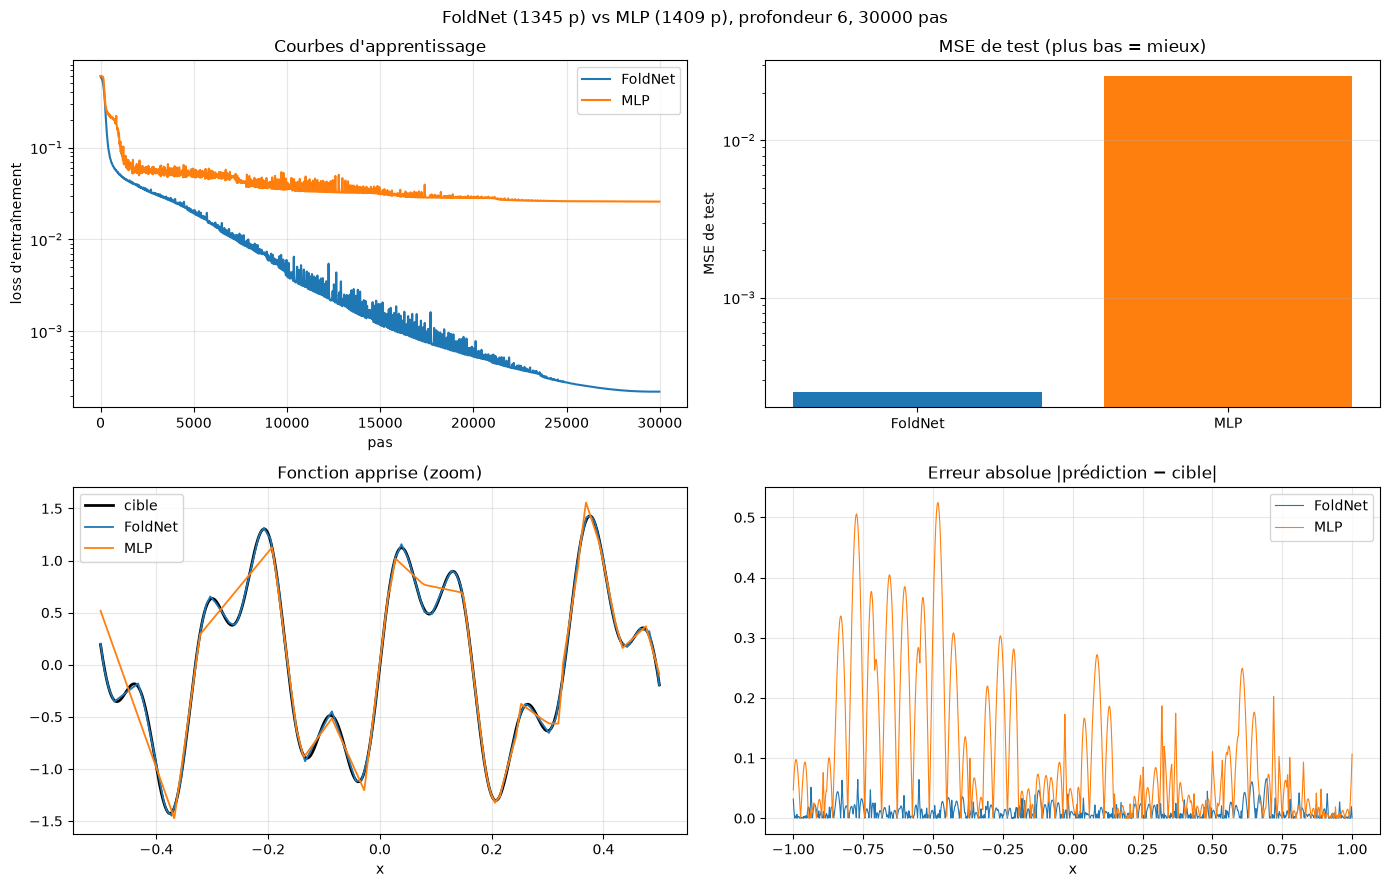

In [11]:
import math

DEV = "cuda" if torch.cuda.is_available() else "cpu"
GRAPH = DEV == "cuda"          # graphe CUDA : un seul lancement GPU par pas
STEPS, LR, DEPTH = 30000, 3e-3, 6
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

class FoldNet(nn.Module):
    """Couches Pliage : y = | M_l x - t_l |,  M_l = H(v_k)...H(v_1),
    avec H(v)x = x - 2 v (v.x)/(v.v). Les matrices M_l sont calculées en lot."""
    def __init__(self, din, dout, d=32, depth=6, k=2):
        super().__init__()
        self.inp = nn.Linear(din, d)
        self.v = nn.Parameter(torch.randn(depth, k, d))
        self.t = nn.Parameter(0.5 * torch.randn(depth, d))
        self.out = nn.Linear(d, dout)
        self.register_buffer("I", torch.eye(d))
    def forward(self, x):
        u = self.v / (self.v.pow(2).sum(-1, keepdim=True) + 1e-8).sqrt()
        M = self.I.expand(self.v.shape[0], -1, -1)
        for i in range(self.v.shape[1]):
            ui = u[:, i]
            M = M - 2 * ui.unsqueeze(-1) @ (ui.unsqueeze(1) @ M)
        Mt = M.transpose(1, 2)
        x = self.inp(x)
        for l in range(self.v.shape[0]):
            x = (x @ Mt[l] - self.t[l]).abs()
        return self.out(x)

class MLP(nn.Module):
    def __init__(self, din, dout, w=32, depth=6):
        super().__init__()
        L = [nn.Linear(din, w), nn.ReLU()]
        for _ in range(depth - 1):
            L += [nn.Linear(w, w), nn.ReLU()]
        L += [nn.Linear(w, dout)]
        self.net = nn.Sequential(*L)
    def forward(self, x):
        return self.net(x)

def n_params(m):
    return sum(p.numel() for p in m.parameters())

def match_mlp(target, din, dout, depth):
    w = min(range(4, 512), key=lambda w: abs(n_params(MLP(din, dout, w, depth)) - target))
    return MLP(din, dout, w, depth)

def f(x):  # cible très oscillante
    return torch.sin(20 * x) + 0.5 * torch.sin(55 * x)

def train(model, name, steps=STEPS, lr=LR):
    model = model.to(DEV)
    x = torch.rand(2048, 1, device=DEV) * 2 - 1
    y = f(x)
    xt = torch.linspace(-1, 1, 8192, device=DEV).unsqueeze(1)
    yt = f(xt)

    lr_t = torch.tensor(lr, device=DEV) if GRAPH else lr
    opt = torch.optim.Adam(model.parameters(), lr=lr_t, capturable=GRAPH)

    def step():
        opt.zero_grad(set_to_none=True)
        loss = ((model(x) - y) ** 2).mean()
        loss.backward()
        opt.step()
        return loss

    if GRAPH:
        # préchauffage (3 pas) sur un flux secondaire, puis capture du pas complet
        s = torch.cuda.Stream()
        s.wait_stream(torch.cuda.current_stream())
        with torch.cuda.stream(s):
            for _ in range(3):
                step()
        torch.cuda.current_stream().wait_stream(s)
        g = torch.cuda.CUDAGraph()
        opt.zero_grad(set_to_none=True)
        with torch.cuda.graph(g):
            static_loss = step()

    losses = torch.empty(steps, device=DEV)
    t0 = time.time()
    pbar = tqdm(range(steps), desc=name)
    for i in pbar:
        lr_i = 0.5 * lr * (1 + math.cos(math.pi * i / steps))   # décroissance en cosinus
        if GRAPH:
            opt.param_groups[0]["lr"].fill_(lr_i)
            g.replay()
            losses[i] = static_loss.detach()
        else:
            opt.param_groups[0]["lr"] = lr_i
            losses[i] = step().detach()
        if i % 100 == 0:
            pbar.set_postfix(loss=f"{losses[i].item():.4f}")
    if DEV == "cuda":
        torch.cuda.synchronize()
    dt = time.time() - t0
    with torch.no_grad():
        pred = model(xt)
        mse = ((pred - yt) ** 2).mean().item()
    return dict(losses=losses.detach().cpu().numpy(), mse=mse, time=dt,
                pred=pred.detach().cpu().numpy().ravel())

def smooth(a, k=25):
    return np.convolve(a, np.ones(k) / k, mode="valid")

if __name__ == "__main__":
    xt = torch.linspace(-1, 1, 8192).unsqueeze(1)
    xs, ys = xt.numpy().ravel(), f(xt).numpy().ravel()

    fold = FoldNet(1, 1, d=64, depth=DEPTH, k=2)
    mlp = match_mlp(n_params(fold), 1, 1, DEPTH)
    pf, pm = n_params(fold), n_params(mlp)
    R = {"FoldNet": train(fold, "FoldNet"), "MLP": train(mlp, "MLP")}
    print(f"FoldNet {pf} p : MSE {R['FoldNet']['mse']:.2e} ({R['FoldNet']['time']:.1f}s)"
          f" | MLP {pm} p : MSE {R['MLP']['mse']:.2e} ({R['MLP']['time']:.1f}s)")

    col = {"FoldNet": "tab:blue", "MLP": "tab:orange"}
    fig, ax = plt.subplots(2, 2, figsize=(14, 9))

    # (a) courbes de loss (lissées)
    for name, r in R.items():
        ax[0, 0].plot(smooth(r["losses"]), color=col[name], label=name)
    ax[0, 0].set_yscale("log"); ax[0, 0].set_xlabel("pas"); ax[0, 0].set_ylabel("loss d'entraînement")
    ax[0, 0].set_title("Courbes d'apprentissage"); ax[0, 0].legend(); ax[0, 0].grid(alpha=0.3)

    # (b) MSE de test
    names = list(R.keys())
    ax[0, 1].bar(names, [R[n]["mse"] for n in names], color=[col[n] for n in names])
    ax[0, 1].set_yscale("log"); ax[0, 1].set_ylabel("MSE de test")
    ax[0, 1].set_title("MSE de test (plus bas = mieux)"); ax[0, 1].grid(alpha=0.3, axis="y")

    # (c) fonction apprise, zoom sur [-0.5, 0.5]
    m = (xs >= -0.5) & (xs <= 0.5)
    ax[1, 0].plot(xs[m], ys[m], "k", lw=2, label="cible")
    for name, r in R.items():
        ax[1, 0].plot(xs[m], r["pred"][m], color=col[name], lw=1.3, label=name)
    ax[1, 0].set_title("Fonction apprise (zoom)"); ax[1, 0].legend(); ax[1, 0].grid(alpha=0.3)
    ax[1, 0].set_xlabel("x")

    # (d) erreur absolue sur tout [-1, 1]
    for name, r in R.items():
        ax[1, 1].plot(xs, np.abs(r["pred"] - ys), color=col[name], lw=0.8, label=name)
    ax[1, 1].set_title("Erreur absolue |prédiction − cible|")
    ax[1, 1].set_xlabel("x"); ax[1, 1].legend(); ax[1, 1].grid(alpha=0.3)

    fig.suptitle(f"FoldNet ({pf} p) vs MLP ({pm} p), profondeur {DEPTH}, {STEPS} pas")
    plt.tight_layout()
    plt.savefig("foldnet_vs_mlp.png", dpi=150)
    plt.show()